**Assignment 1 – Heart Disease (Cleveland Database)**

Group9: Hatice AY, Bedia Nur ELMAS, Mahyar Naeimi

The file processed.cleveland.data must be in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "processed.cleveland.data"       # relative path to the provided dataset
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS, na_values="?")   # "?" = missing value
print(df.shape)

(303, 14)


**Pipeline, models and evaluation functions**

Same pre-processing, classifiers and evaluation as in Task 2.

In [2]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42

features = [c for c in df.columns if c != "num"]
X = df[features]
y_multi = df["num"].values

NOMINAL = ["cp", "restecg", "slope", "thal"]      # labels, not real numbers -> one-hot
OTHER = [c for c in features if c not in NOMINAL]

def make_preprocessor():
    nominal = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    other = Pipeline([("impute", SimpleImputer(strategy="most_frequent"))])
    return Pipeline([("columns", ColumnTransformer([("nom", nominal, NOMINAL),
                                                    ("oth", other, OTHER)])),
                     ("scale", StandardScaler())])

def make_models():
    return {
        "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "kNN (k=15)": KNeighborsClassifier(n_neighbors=15),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        "SVM (RBF)": SVC(kernel="rbf", random_state=RANDOM_STATE),
    }

def pipe(model):
    # preprocessing is fitted on the training folds only -> no data leakage
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

def sens_spec(y_true, y_pred, labels):
    # one-vs-rest sensitivity and specificity per class, then macro average
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - tp - fn - fp
    with np.errstate(invalid="ignore", divide="ignore"):
        sens = tp / (tp + fn)
        spec = tn / (tn + fp)
    if len(labels) == 2:                      # binary case: positive class = 1
        return sens[1], spec[1]
    return np.nanmean(sens), np.nanmean(spec)

def evaluate(y, labels):
    # stratified 5-fold CV, repeated 10 times = 50 train/test splits
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
    rows = []
    for name, model in make_models().items():
        for tr, te in cv.split(X, y):
            m = pipe(clone(model)).fit(X.iloc[tr], y[tr])
            pred = m.predict(X.iloc[te])
            se, sp = sens_spec(y[te], pred, labels)
            rows.append({"model": name, "accuracy": accuracy_score(y[te], pred),
                         "sensitivity": se, "specificity": sp})
    return pd.DataFrame(rows)

def grouped_bar(res, title):
    long = res.melt(id_vars="model", var_name="metric", value_name="value")
    fig, ax = plt.subplots(figsize=(11, 4.5))
    sns.barplot(data=long, x="model", y="value", hue="metric", errorbar="sd", capsize=0.1, ax=ax)
    ax.set(ylim=(0, 1), ylabel="mean ± SD over CV folds", xlabel="", title=title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    for c in ax.containers:
        if hasattr(c, "datavalues"):
            ax.bar_label(c, fmt="%.2f", fontsize=8, label_type="center", color="white")
    plt.tight_layout()
    plt.show()

def confusion_heatmaps(y, labels, title):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    models = {k: v for k, v in make_models().items() if not k.startswith("Baseline")}
    fig, axes = plt.subplots(1, len(models), figsize=(4.3 * len(models), 4))
    preds = {}
    for ax, (name, model) in zip(axes, models.items()):
        pred = cross_val_predict(pipe(model), X, y, cv=cv)
        preds[name] = pred
        cm = confusion_matrix(y, pred, labels=labels)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=labels, yticklabels=labels)
        ax.set(title=f"{name}\nacc = {accuracy_score(y, pred):.2f}",
               xlabel="predicted", ylabel="true")
    plt.suptitle(title, y=1.04)
    plt.tight_layout()
    plt.show()
    return preds

**Task 3 – Heart disease vs. no heart disease**

We repeat Task 2 with only two classes: 0 = no disease (num = 0) and 1 = disease (num = 1 to 4). Sensitivity is now the share of diseased patients that are detected, specificity the share of healthy patients that are classified as healthy.

no disease    164
disease       139
Name: count, dtype: int64


                         accuracy        sensitivity        specificity       
                             mean    std        mean    std        mean    std
model                                                                         
Baseline (most frequent)    0.541  0.005       0.000  0.000       1.000  0.000
Logistic Regression         0.834  0.041       0.783  0.062       0.876  0.055
kNN (k=15)                  0.832  0.043       0.800  0.062       0.860  0.058
Random Forest               0.826  0.053       0.779  0.078       0.865  0.066
SVM (RBF)                   0.829  0.046       0.789  0.066       0.864  0.062


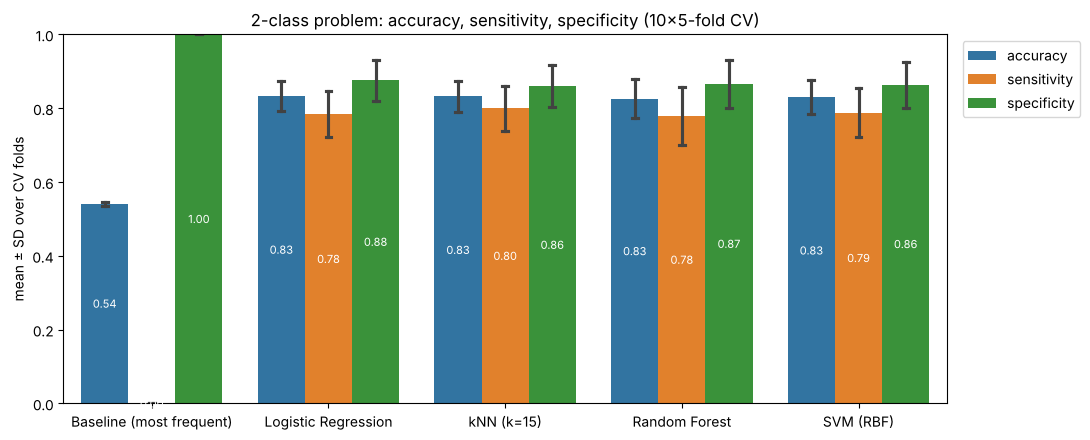

In [3]:
y_bin = (df["num"] > 0).astype(int).values
print(pd.Series(y_bin).value_counts().rename({0: "no disease", 1: "disease"}))

res_bin = evaluate(y_bin, labels=[0, 1])
print(res_bin.groupby("model", sort=False).agg(["mean", "std"]).round(3))
grouped_bar(res_bin, "2-class problem: accuracy, sensitivity, specificity (10x5-fold CV)")

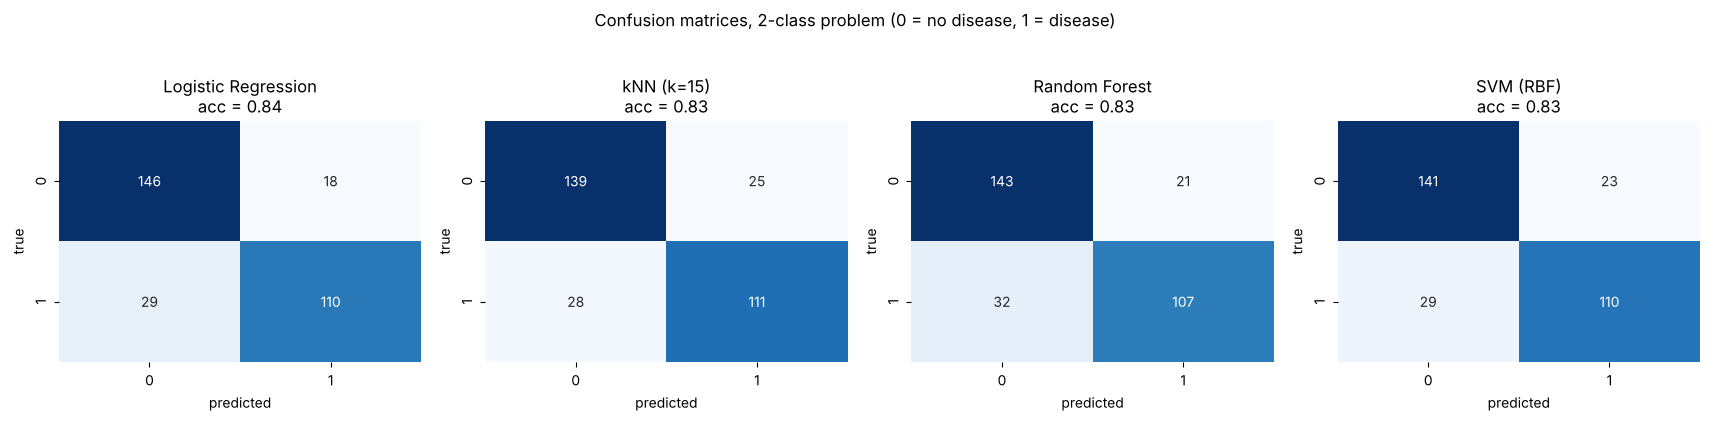

In [4]:
preds_bin = confusion_heatmaps(y_bin, [0, 1], "Confusion matrices, 2-class problem (0 = no disease, 1 = disease)")

**Comparison with the 5-class models**

We also take the predictions of the 5-class models from Task 2, merge the classes 1 to 4 into "disease", and compare their accuracy with the binary models.

In [5]:
y_multi = df["num"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in make_models().items():
    if name.startswith("Baseline"):
        continue
    pred_multi = cross_val_predict(pipe(model), X, y_multi, cv=cv)
    rows.append({"model": name,
                 "5-class model, merged to 2 classes": accuracy_score(y_bin, (pred_multi > 0).astype(int)),
                 "binary model": accuracy_score(y_bin, preds_bin[name])})
print(pd.DataFrame(rows).set_index("model").round(3))

                     5-class model, merged to 2 classes  binary model
model                                                                
Logistic Regression                               0.842         0.845
kNN (k=15)                                        0.785         0.825
Random Forest                                     0.782         0.825
SVM (RBF)                                         0.766         0.828


**Analysis**

With two classes the accuracy rises from about 0.58 to about 0.83, the sensitivity from about 0.3 to about 0.79, and the specificity stays around 0.87. All four models perform almost equally. The baseline now has sensitivity 0 and specificity 1 because it always predicts "no disease", which shows that accuracy alone is not enough.

The change works because both classes are now large and almost balanced (164 vs. 139), and because the features separate healthy from diseased patients well, but not the severity classes (see IDA step 7). Even the 5-class models reach a much higher accuracy when their predictions are merged to two classes, but the models trained directly on the binary question are still as good or better.

Does it make sense? Yes. Clinically, the first question is whether a patient has a significant narrowing of a coronary artery, and this is also the definition used by Detrano et al. (1989). With only 13 to 36 patients per severity class, a 5-class model cannot be learned reliably. The disadvantage is that we lose information: a patient with severe disease is treated the same as a patient with mild disease, and the order of the classes is ignored. Also, a missed disease (false negative) is worse than a false alarm (false positive), so in practice one would choose a threshold with a higher sensitivity (see Task 4).